In [1]:
from __future__ import annotations
from pathlib import Path
import pandas as pd
import numpy as np
import re
import seaborn as sns
import matplotlib.pyplot as plt

import sys
modules_path = Path.cwd().parent / "modules"
sys.path.append(str(modules_path))
import basicmlp
from load_results import load_results, save_cache

In [2]:
date="20260625"

### Import Datasets and Embeddings

In [3]:
results_df= load_results("../07_OUTPUTS/", date=date)
save_cache(results_df, outputs_root="../07_OUTPUTS/", date=date)

PosixPath('../07_OUTPUTS/20260625/compiled/results.parquet')

In [4]:
results_df[results_df["dataset"]=="MQM_IS"]

,date,dataset_from_path,model_from_path,embedding_from_path,split_dir,summary_path,split_method_from_path,split_seed_from_path,dataset,model,...,outdir,train_MAE,train_RMSE,train_R2,test_MAE,test_RMSE,test_R2,train_MSE,test_MSE,run_id


In [5]:
df = results_df.copy() #[results_df["model"] == "linear"].copy()

# remove values with rmse > 100
df = df[df["test_R2"] > -0.5]

renamed_embeddings = {
    "morgan_fps": "ECFP4",
    "hq_descriptor": "QU",
    "chemeleon": "CheMeleon",
    "molclr": "MolCLR",
    "maceoff_large": "MACE OFF",
}

df["embedding"] = df["embedding"].map(renamed_embeddings)

desired_order_clean = [
    "ECFP4",
    "QU",
    "CheMeleon",
    "MolCLR",
    "MACE OFF"
]
df["embedding"] = pd.Categorical(df["embedding"], categories=desired_order_clean, ordered=True)

renamed_models = {
    "linear": "LR",
    "rf": "RF",
    "xgboost": "XGB",
    "mlp": "MLP",
}

desired_model_order = [
    "LR",
    "RF",
    "XGB",
    "MLP",
]
df["model"] = df["model"].map(renamed_models)
df["model"] = pd.Categorical(df["model"], categories=desired_model_order, ordered=True)


renamed_dataset = {
    "CD": r"$\rho_{cryst}$"
}
df["dataset"] = df["dataset"].map(renamed_dataset).fillna(df["dataset"])
desired_dataset_order = [
    r"$\rho_{cryst}$",
    "HOF",
    "IS",
]
df["dataset"] = pd.Categorical(df["dataset"], categories=desired_dataset_order, ordered=True)


/tmp/ipykernel_2201/1194568007.py:29: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(
/tmp/ipykernel_2201/1194568007.py:29: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(
/tmp/ipykernel_2201/1194568007.py:29: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.barplot(


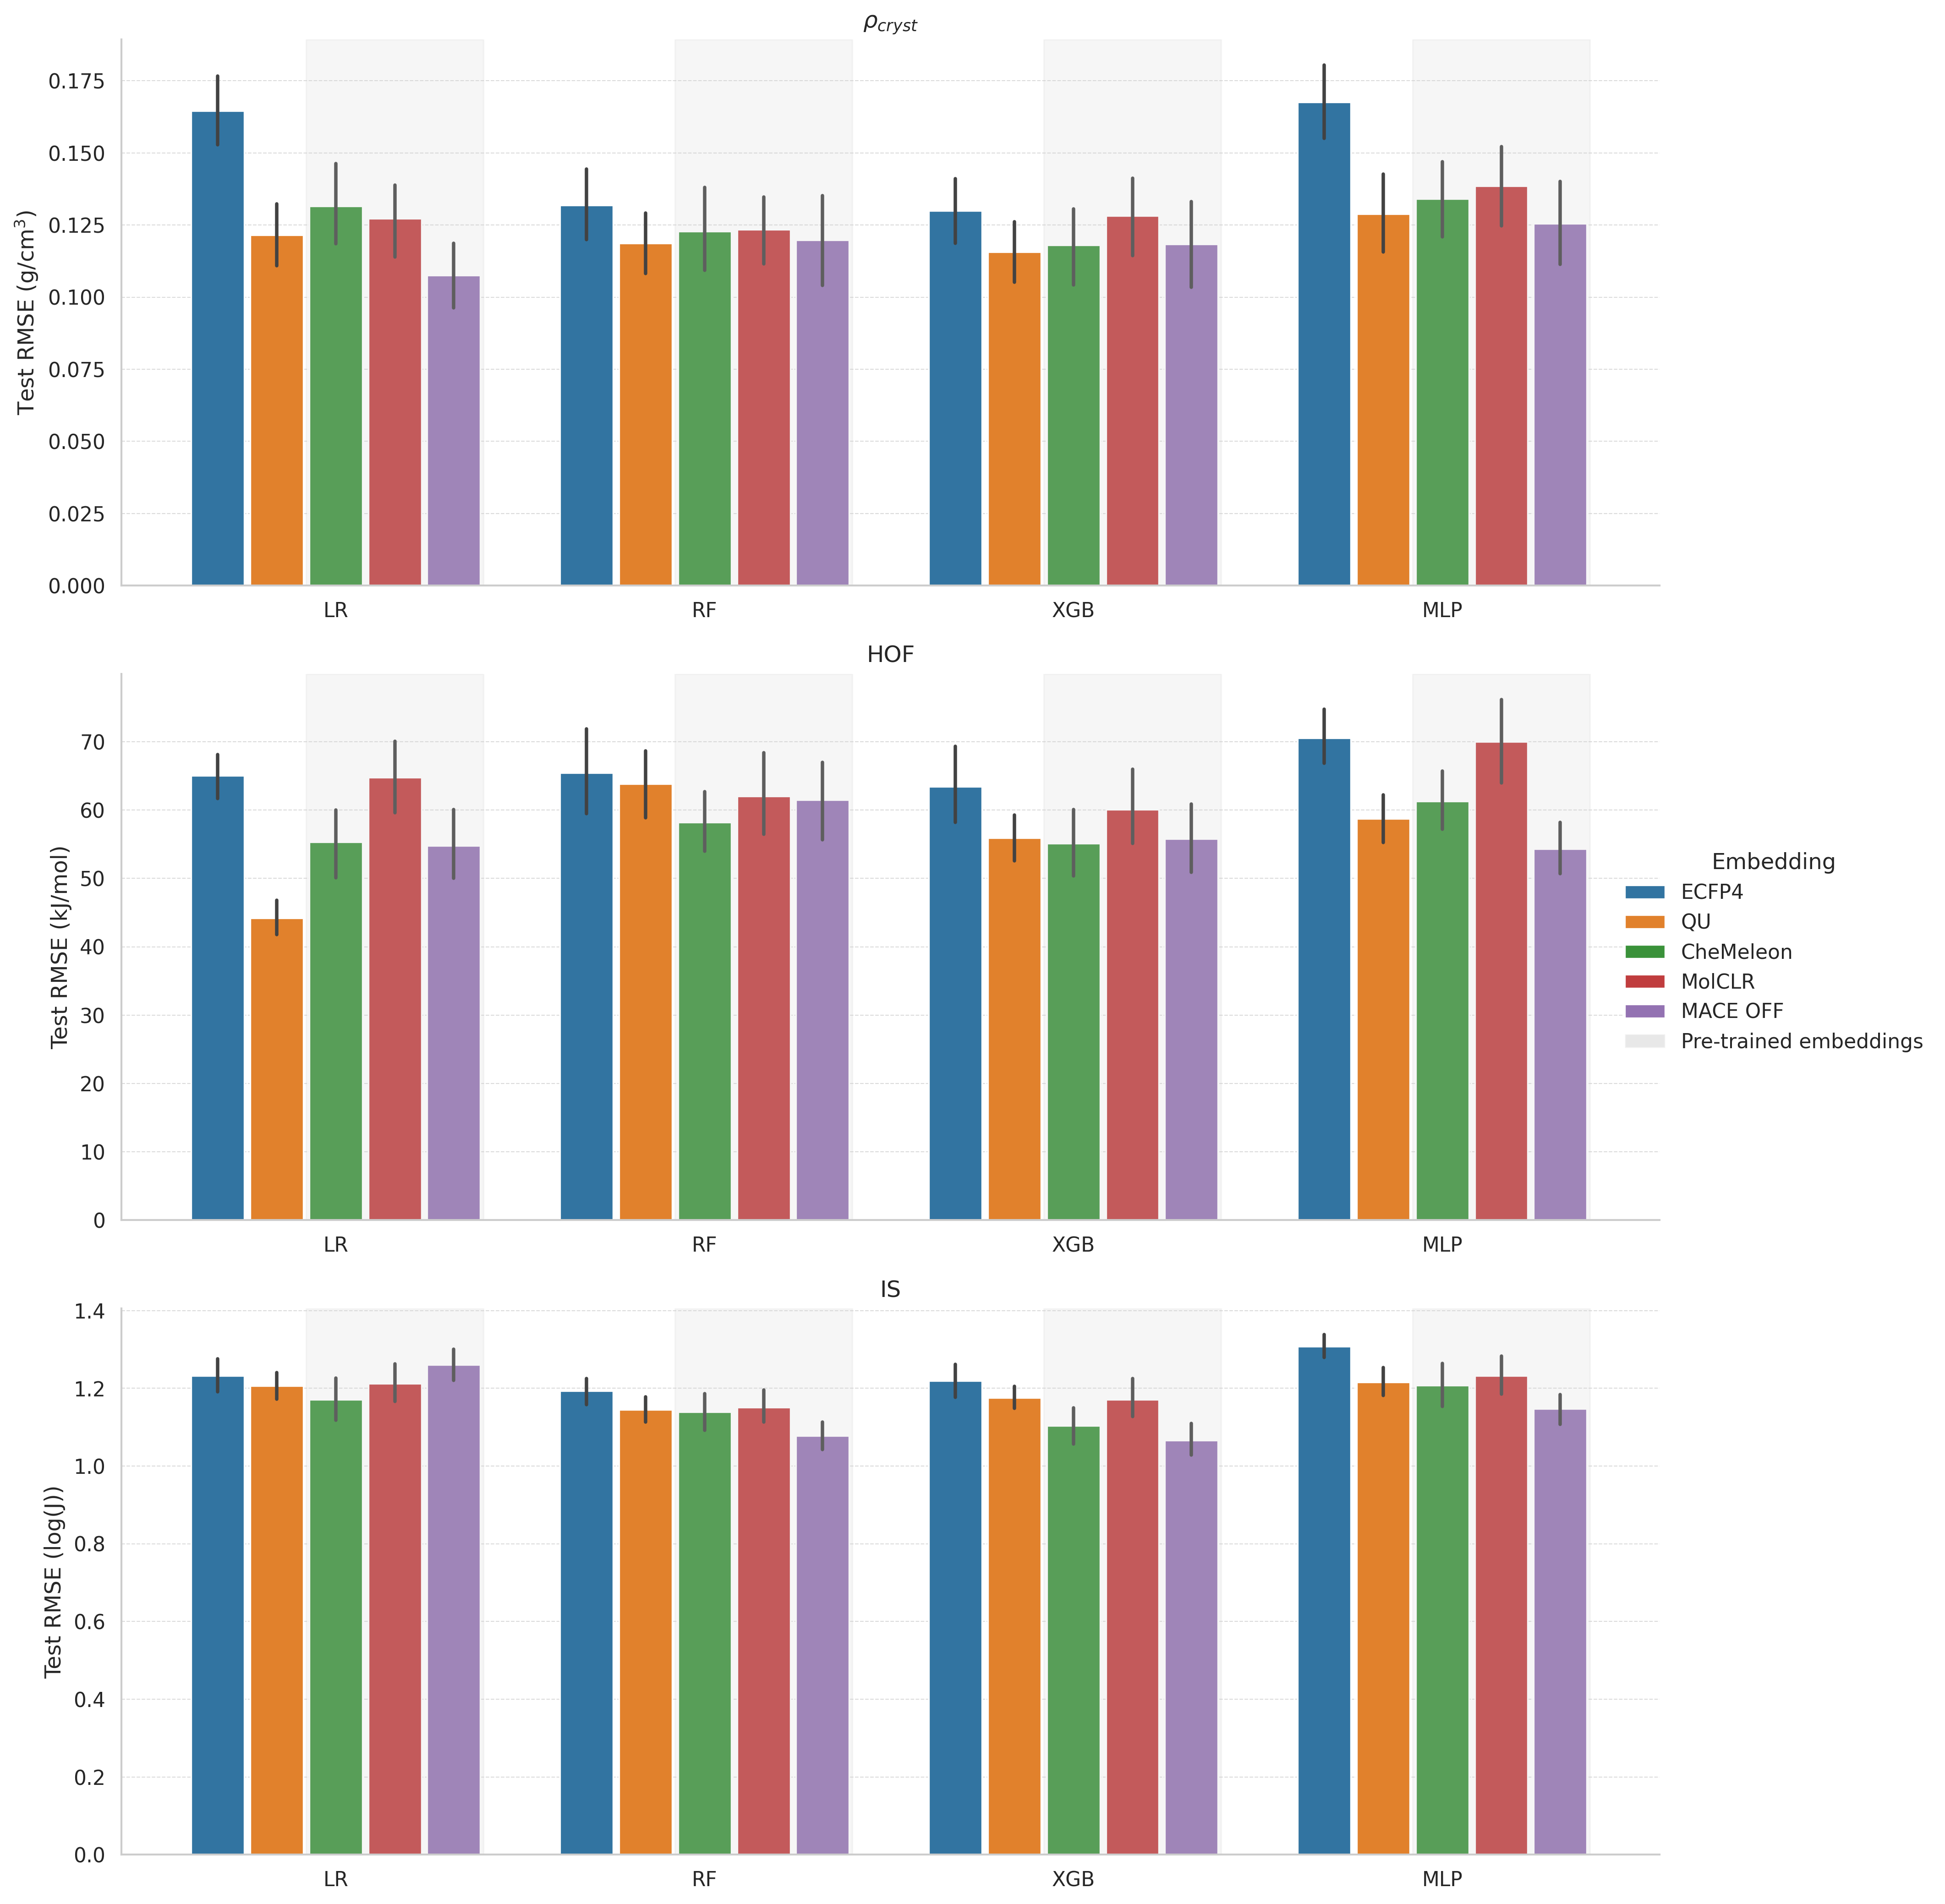

In [6]:
from matplotlib.patches import Patch

# Publication-style defaults
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)

palette = sns.color_palette("tab10")
datasets = desired_dataset_order
models = desired_model_order

embedding_order = [
    "ECFP4",
    "QU",
    "CheMeleon",
    "MolCLR",
    "MACE OFF",
]
pretrained_embeddings = {"CheMeleon", "MolCLR", "MACE OFF"}

fig, axes = plt.subplots(
    len(datasets), 1, figsize=(14, 14), sharey=False, dpi=300
)

legend_handles = None
legend_labels = None

for ax, ds in zip(axes, datasets):
    sub = df[df["dataset"] == ds]

    sns.barplot(
        data=sub,
        x="model",
        y="test_RMSE",
        hue="embedding",
        hue_order=embedding_order,
        palette=palette,
        errorbar="ci",
        ax=ax,
        gap=0.1
    )

    # Shade the contiguous pre-trained embeddings within each model group.
    n_embeddings = len(embedding_order)
    group_width = 0.8
    bar_width = group_width / n_embeddings
    pretrained_start = min(
        embedding_order.index(name) for name in pretrained_embeddings
    )
    pretrained_end = max(
        embedding_order.index(name) for name in pretrained_embeddings
    )

    for x_position in ax.get_xticks():
        left = (
            x_position
            - group_width / 2
            + pretrained_start * bar_width
        )
        right = (
            x_position
            - group_width / 2
            + (pretrained_end + 1) * bar_width
        )

        ax.axvspan(
            left,
            right,
            color="lightgray",
            alpha=0.2,
            zorder=0,
        )

    # Ensure bars and their error bars appear above the shading.
    for patch in ax.patches:
        patch.set_zorder(2)
    for container in ax.containers:
        if hasattr(container, "errorbar") and container.errorbar is not None:
            for artist_group in container.errorbar.lines:
                if artist_group:
                    for artist in artist_group:
                        artist.set_zorder(3)

    ax.set_title(f"{ds}", fontsize=12)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.7)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if ax is axes[0]:
        ax.set_ylabel("Test RMSE (g/cm$^3$)")
    elif ax is axes[1]:
        ax.set_ylabel("Test RMSE (kJ/mol)")
    else:
        ax.set_ylabel("Test RMSE (log(J))")

    if legend_handles is None:
        legend_handles, legend_labels = ax.get_legend_handles_labels()

    ax.legend_.remove()

# Add shading entry to the shared legend.
legend_handles.append(
    Patch(
        facecolor="lightgray",
        alpha=0.5,
        label="Pre-trained embeddings",
    )
)
legend_labels.append("Pre-trained embeddings")

fig.legend(
    legend_handles,
    legend_labels,
    loc="center left",
    bbox_to_anchor=(0.84, 0.5),
    frameon=False,
    title="Embedding",
)

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

# Comparison across regressors

### Are the FMs equal to or better than the hand-crafted descriptor?

One-sided paired t-test on matched split and model-seed runs. Lower RMSE is better. The result is significant only when HC has significantly lower RMSE than the FM; otherwise, the FM is treated as equal or better.

In [7]:
from scipy.stats import ttest_rel

In [8]:
df_clean = df[["dataset", "model", "seed", "split_method", "embedding", "test_MAE", "test_RMSE", "test_R2"]].copy()
df_clean = df_clean[df_clean["dataset"].isin(['HOF', "IS", "MQM_IS", r'$\rho_{cryst}$'])]

# select random splits only
df_random_splits = df_clean[df_clean["split_method"].str.contains("random", case=False, na=False)].copy()
df_random_splits.groupby(["dataset", "embedding"])[["test_RMSE", "test_R2"]].agg(["mean", "std"]).round(3)

/tmp/ipykernel_2201/2387110868.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_random_splits.groupby(["dataset", "embedding"])[["test_RMSE", "test_R2"]].agg(["mean", "std"]).round(3)


test_RMSE         test_R2       
                              mean     std    mean    std
dataset        embedding                                 
$\rho_{cryst}$ ECFP4         0.136   0.025   0.297  0.147
               QU            0.120   0.027   0.460  0.128
               CheMeleon     0.124   0.029   0.421  0.171
               MolCLR        0.122   0.028   0.440  0.137
               MACE OFF      0.112   0.032   0.536  0.158
HOF            ECFP4        63.905  10.901   0.588  0.099
               QU           53.069  11.429   0.708  0.110
               CheMeleon    54.505  12.627   0.694  0.124
               MolCLR       59.297  11.337   0.639  0.128
               MACE OFF     52.663  11.383   0.721  0.081
IS             ECFP4         1.142   0.078   0.258  0.107
               QU            1.122   0.039   0.286  0.051
               CheMeleon     1.034   0.057   0.393  0.062
               MolCLR        1.064   0.060   0.357  0.067
               MACE OFF      1.036   0.100   0.386  0.123

In [9]:
ALPHA = 0.05
FM_EMBEDDINGS = ["ECFP4", "CheMeleon", "MolCLR", "MACE OFF"]
# aggregate across models, comparing each FM embedding to the hand-crafted QU descriptors
model_aggregated = df_random_splits.groupby(["dataset", "model", "embedding", "seed", "split_method"])[["test_RMSE"]].mean().reset_index()
# xgb = df_clean[df_clean["model"] == "XGB"].copy()

records = []
for dataset in model_aggregated["dataset"].unique():
    dataset_scores = model_aggregated[model_aggregated["dataset"] == dataset]
    hc = (
        dataset_scores[dataset_scores["embedding"] == "QU"]
        [["split_method", "seed", "test_RMSE"]]
        .rename(columns={"test_RMSE": "hc_RMSE"})
    )

    for fm in FM_EMBEDDINGS:
        fm_scores = (
            dataset_scores[dataset_scores["embedding"] == fm]
            [["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "fm_RMSE"})
        )
        paired = fm_scores.merge(
            hc, on=["split_method", "seed"], how="inner"
        ).dropna()
        if len(paired) < 2:
            raise ValueError(f"Need at least two paired runs for {dataset=}, {fm=}")

        test = ttest_rel(
            paired["hc_RMSE"], paired["fm_RMSE"], alternative="less"
        )

        records.append({
            "dataset": dataset,
            "embedding": fm,
            "n_pairs": len(paired),
            "mean_hc_RMSE": paired["hc_RMSE"].mean(),
            "mean_fm_RMSE": paired["fm_RMSE"].mean(),
            "t_stat": test.statistic,
            "p_value": test.pvalue,
            "significance": "significant" if test.pvalue < ALPHA else "not significant",
            "result": "HC better than FM" if test.pvalue < ALPHA else "FM equal or better than HC",
        })

comparison_results = pd.DataFrame(records)

one_table = (
    comparison_results
    .sort_values(["dataset", "embedding"])
    .rename(columns={
        "dataset": "Dataset",
        "embedding": "FM",
        "n_pairs": "Paired runs",
        "mean_hc_RMSE": "HC mean RMSE",
        "mean_fm_RMSE": "FM mean RMSE",
        "t_stat": "t statistic",
        "p_value": "p value",
        "significance": "Significance",
        "result": "Result",
    })
)
display(one_table.set_index(["Dataset", "FM"]).round(3))

/tmp/ipykernel_2201/1805980001.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  model_aggregated = df_random_splits.groupby(["dataset", "model", "embedding", "seed", "split_method"])[["test_RMSE"]].mean().reset_index()


Paired runs  HC mean RMSE  FM mean RMSE  \
Dataset        FM                                                   
$\rho_{cryst}$ CheMeleon          400         0.120         0.124   
               ECFP4              400         0.120         0.136   
               MACE OFF           400         0.120         0.112   
               MolCLR             400         0.120         0.122   
HOF            CheMeleon          400        53.069        54.505   
               ECFP4              400        53.069        63.905   
               MACE OFF           400        53.069        52.663   
               MolCLR             400        53.069        59.297   
IS             CheMeleon          400         1.122         1.034   
               ECFP4              400         1.122         1.142   
               MACE OFF           380         1.123         1.036   
               MolCLR             400         1.122         1.064   

                          t statistic  p value     Significance  \
Dataset        FM                                                 
$\rho_{cryst}$ CheMeleon       -4.752    0.000      significant   
               ECFP4          -18.421    0.000      significant   
               MACE OFF        15.257    1.000  not significant   
               MolCLR          -3.708    0.000      significant   
HOF            CheMeleon       -2.102    0.018      significant   
               ECFP4          -17.159    0.000      significant   
               MACE OFF         0.635    0.737  not significant   
               MolCLR          -9.534    0.000      significant   
IS             CheMeleon       27.915    1.000  not significant   
               ECFP4           -4.648    0.000      significant   
               MACE OFF        16.497    1.000  not significant   
               MolCLR          16.269    1.000  not significant   

                                              Result  
Dataset        FM                                     
$\rho_{cryst}$ CheMeleon           HC better than FM  
               ECFP4               HC better than FM  
               MACE OFF   FM equal or better than HC  
               MolCLR              HC better than FM  
HOF            CheMeleon           HC better than FM  
               ECFP4               HC better than FM  
               MACE OFF   FM equal or better than HC  
               MolCLR              HC better than FM  
IS             CheMeleon  FM equal or better than HC  
               ECFP4               HC better than FM  
               MACE OFF   FM equal or better than HC  
               MolCLR     FM equal or better than HC

In [10]:
## compare each embedding to the best performer for that dataset, using paired t-tests
from scipy.stats import ttest_rel
from statsmodels.stats.multitest import multipletests
import pandas as pd

ALPHA = 0.05
EMBEDDINGS = ["QU", "ECFP4", "CheMeleon", "MolCLR", "MACE OFF"]

# Select random splits only
df_random_splits = df_clean[
    df_clean["split_method"].str.contains("random", case=False, na=False)
].copy()

# Average across models, retaining paired experimental runs
model_aggregated = (
    df_random_splits[
        df_random_splits["embedding"].isin(EMBEDDINGS)
    ]
    .groupby(
        ["dataset", "embedding", "seed", "split_method"],
        as_index=False,
    )["test_RMSE"]
    .mean()
)

records = []

for dataset, dataset_scores in model_aggregated.groupby("dataset"):

    # Determine the empirically best embedding: lowest overall mean RMSE
    embedding_means = (
        dataset_scores
        .groupby("embedding")["test_RMSE"]
        .mean()
        .sort_values()
    )

    best_embedding = embedding_means.index[0]

    best_scores = (
        dataset_scores[dataset_scores["embedding"] == best_embedding]
        [["split_method", "seed", "test_RMSE"]]
        .rename(columns={"test_RMSE": "best_RMSE"})
    )

    dataset_records = []

    for embedding in embedding_means.index[1:]:
        other_scores = (
            dataset_scores[dataset_scores["embedding"] == embedding]
            [["split_method", "seed", "test_RMSE"]]
            .rename(columns={"test_RMSE": "other_RMSE"})
        )

        paired = (
            best_scores
            .merge(other_scores, on=["split_method", "seed"], how="inner")
            .dropna()
        )

        if len(paired) < 2:
            raise ValueError(
                f"Need at least two paired runs for "
                f"dataset={dataset!r}, embedding={embedding!r}"
            )

        # H1: best embedding has lower RMSE than the other embedding
        test = ttest_rel(
            paired["best_RMSE"],
            paired["other_RMSE"],
            alternative="less",
        )

        dataset_records.append({
            "dataset": dataset,
            "best_embedding": best_embedding,
            "embedding": embedding,
            "n_pairs": len(paired),
            "mean_best_RMSE": paired["best_RMSE"].mean(),
            "mean_other_RMSE": paired["other_RMSE"].mean(),
            "mean_difference": (
                paired["other_RMSE"] - paired["best_RMSE"]
            ).mean(),
            "t_stat": test.statistic,
            "p_value": test.pvalue,
        })

    # Correct for testing several embeddings against the winner
    if dataset_records:
        adjusted = multipletests(
            [record["p_value"] for record in dataset_records],
            alpha=ALPHA,
            method="holm",
        )

        for record, reject, adjusted_p in zip(
            dataset_records, adjusted[0], adjusted[1]
        ):
            record["adjusted_p_value"] = adjusted_p
            record["significantly_worse"] = bool(reject)
            record["result"] = (
                "Significantly worse than best"
                if reject
                else "Not significantly worse than best"
            )

        records.extend(dataset_records)

comparison_results = pd.DataFrame(records)

one_table = (
    comparison_results
    .sort_values(["dataset", "embedding"])
    .rename(columns={
        "dataset": "Dataset",
        "best_embedding": "Best embedding",
        "embedding": "Compared embedding",
        "n_pairs": "Paired runs",
        "mean_best_RMSE": "Best mean RMSE",
        "mean_other_RMSE": "Other mean RMSE",
        "mean_difference": "RMSE difference",
        "t_stat": "t statistic",
        "p_value": "Raw p value",
        "adjusted_p_value": "Holm-adjusted p value",
        "significantly_worse": "Significantly worse",
        "result": "Result",
    })
)

display(
    one_table
    .set_index(["Dataset", "Best embedding", "Compared embedding"])
    .round(3)
)

/tmp/ipykernel_2201/1495973714.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(
/tmp/ipykernel_2201/1495973714.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for dataset, dataset_scores in model_aggregated.groupby("dataset"):
/tmp/ipykernel_2201/1495973714.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("embedding")["test_RMSE"]
/tmp/ipykernel_2201/1495973714.py:33: FutureWarning: The de

Paired runs  Best mean RMSE  \
Dataset        Best embedding Compared embedding                                
$\rho_{cryst}$ MACE OFF       CheMeleon                    25           0.112   
                              ECFP4                        25           0.112   
                              MolCLR                       25           0.112   
                              QU                           25           0.112   
HOF            MACE OFF       CheMeleon                    25          52.663   
                              ECFP4                        25          52.663   
                              MolCLR                       25          52.663   
                              QU                           25          52.663   
IS             MACE OFF       CheMeleon                    25           1.034   
                              ECFP4                        25           1.034   
                              MolCLR                       25           1.034   
                              QU                           25           1.034   

                                                  Other mean RMSE  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ MACE OFF       CheMeleon                     0.124   
                              ECFP4                         0.136   
                              MolCLR                        0.122   
                              QU                            0.120   
HOF            MACE OFF       CheMeleon                    54.505   
                              ECFP4                        63.905   
                              MolCLR                       59.297   
                              QU                           53.069   
IS             MACE OFF       CheMeleon                     1.034   
                              ECFP4                         1.142   
                              MolCLR                        1.064   
                              QU                            1.122   

                                                  RMSE difference  \
Dataset        Best embedding Compared embedding                    
$\rho_{cryst}$ MACE OFF       CheMeleon                     0.013   
                              ECFP4                         0.025   
                              MolCLR                        0.011   
                              QU                            0.009   
HOF            MACE OFF       CheMeleon                     1.842   
                              ECFP4                        11.241   
                              MolCLR                        6.634   
                              QU                            0.406   
IS             MACE OFF       CheMeleon                     0.001   
                              ECFP4                         0.108   
                              MolCLR                        0.031   
                              QU                            0.088   

                                                  t statistic  Raw p value  \
Dataset        Best embedding Compared embedding                             
$\rho_{cryst}$ MACE OFF       CheMeleon                -6.476        0.000   
                              ECFP4                    -9.818        0.000   
                              MolCLR                  -10.152        0.000   
                              QU                       -7.854        0.000   
HOF            MACE OFF       CheMeleon                -1.608        0.060   
                              ECFP4                   -16.428        0.000   
                              MolCLR                   -5.161        0.000   
                              QU                       -0.345        0.367   
IS             MACE OFF       CheMeleon                -0.132        0.448   
                              ECFP4                   -14.194        0.000   
                              MolCLR         

# win count table

In [11]:
def embedding_wins_and_avg_rank(
    df: pd.DataFrame,
    metric: str = "test_MAE",
    group_cols=("model", "dataset",),
    method: str = "average",  # rank tie handling
):
    d = df.copy()

    # Rank embeddings within each (dataset, model, seed, Split Method)
    d["rank"] = d.groupby(list(group_cols))[metric].rank(method=method, ascending=True)

    # Win = rank == 1 (ties count as wins for all tied embeddings)
    d["win"] = (d["rank"] == 1).astype(int)

    return d.groupby(["embedding"]).agg(
        win_count=("win", "sum"),
        avg_rank=("rank", "mean"),
    ).sort_values(["win_count", "avg_rank"], ascending=[False, True])

#aggregate over seed
seed_aggregated_df = df_random_splits.groupby(["dataset", "model", "embedding"], as_index=False)["test_RMSE"].mean()

ranking_mae = embedding_wins_and_avg_rank(seed_aggregated_df, metric="test_RMSE").round(2)
ranking_mae.columns = ["Win Count", "Avg Rank"]
# set sig fige to 2 on Avg Rank column
ranking_mae["Avg Rank"] = ranking_mae["Avg Rank"]
ranking_mae.sort_index(axis=1).reindex(['Win Count', 'Avg Rank'], level=1, axis=1)

/tmp/ipykernel_2201/4205394912.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  seed_aggregated_df = df_random_splits.groupby(["dataset", "model", "embedding"], as_index=False)["test_RMSE"].mean()
/tmp/ipykernel_2201/4205394912.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  d["rank"] = d.groupby(list(group_cols))[metric].rank(method=method, ascending=True)
/tmp/ipykernel_2201/4205394912.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default

,Win Count,Avg Rank
embedding,,
MACE OFF,7,1.75
CheMeleon,2,2.50
QU,2,3.17
MolCLR,1,2.83
ECFP4,0,4.75


## evaluate penalties from harder splits

/tmp/ipykernel_2201/3773772991.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rand_grouped = rand_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()
/tmp/ipykernel_2201/3773772991.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  scaff_grouped = scaff_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()
/tmp/ipykernel_2201/3773772991.py:36: UserWarning: The palette list has more values (10) than needed (5), which may not be intended.
  sns.pointplot(
/tmp/ipykernel_2201/3773772991

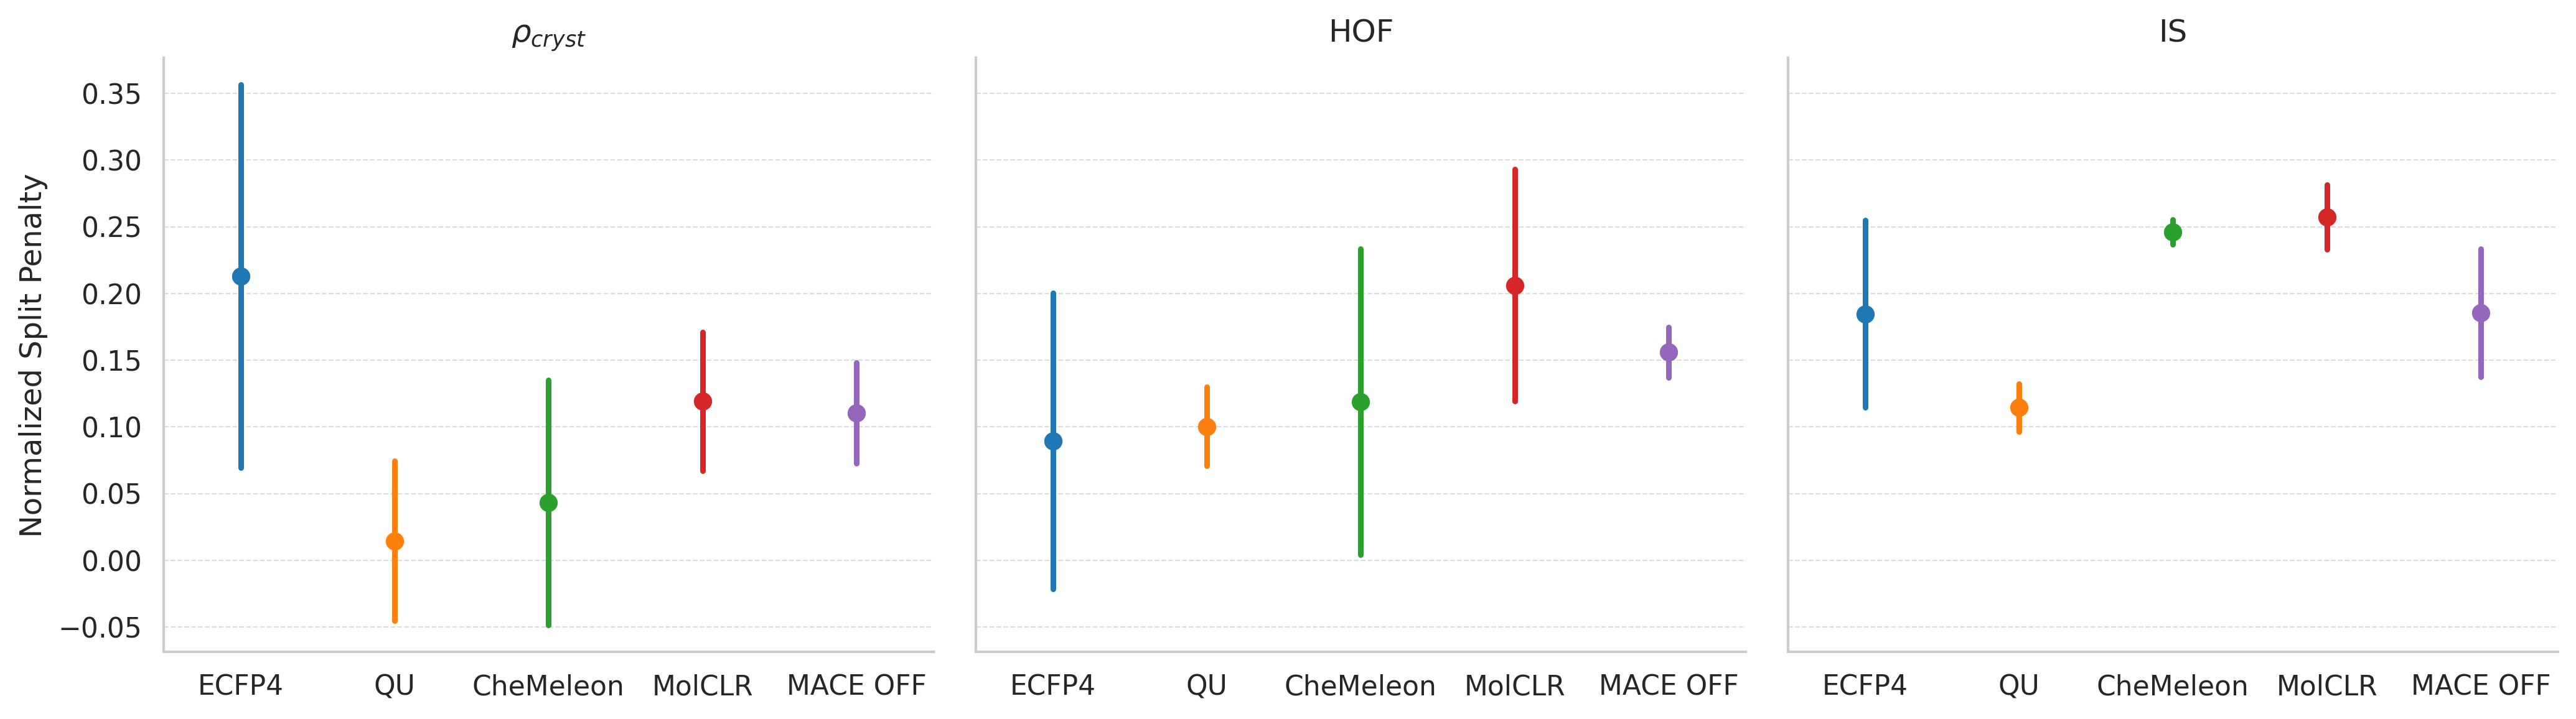

In [12]:
rand_splits = df[df["split_method"].str.contains("random_seed")].copy()
rand_grouped = rand_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()

scaff_splits = df[df["split_method"].str.contains("cluster")].copy()
scaff_grouped = scaff_splits.groupby(["dataset", "embedding", "model"], as_index=False)["test_RMSE"].agg(["mean", "std"]).reset_index()

# --- compute normalized split penalty (robust merge vs relying on matching indices) ---
tmp = rand_grouped.merge(
    scaff_grouped[["dataset", "embedding", "model", "mean"]],
    on=["dataset", "embedding", "model"],
    suffixes=("_rand", "_scaff"),
)

tmp["split_penalty"] = tmp["mean_scaff"] - tmp["mean_rand"]
tmp["Normalized Split Penalty"] = tmp["split_penalty"] / tmp["mean_rand"]

# --- publication-style defaults ---
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
palette = sns.color_palette("tab10")  # colorblind-friendly, print-safe

datasets = desired_dataset_order
emb_order = desired_order_clean if "desired_order_clean" in globals() else list(tmp["embedding"].unique())

fig, axes = plt.subplots(
    1, len(datasets),
    figsize=(14, 4),
    sharey=True,
    dpi=300,
)

# If there's only 1 dataset, axes won't be iterable by default
axes = np.atleast_1d(axes)

for ax, ds in zip(axes, datasets):
    sub = tmp[tmp["dataset"] == ds]
    sns.pointplot(
        data=sub,
        x="embedding",
        y="Normalized Split Penalty",
        hue="embedding",
        order=emb_order,
        errorbar="sd",
        ax=ax,
        palette=palette,
        markers="o",
        linestyles=None,
    )

    ax.set_title(f"{ds}", fontsize=12)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.7)

    # Clean spines (publication style)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # Only keep ylabel on first plot
    if ax is axes[0]:
        ax.set_ylabel("Normalized Split Penalty")
    else:
        ax.set_ylabel("")

plt.tight_layout()
plt.show()

In [13]:
tmp.drop("index", axis=1).groupby(["dataset", "embedding"])[["Normalized Split Penalty"]].agg(["mean", "std"]).round(3)

/tmp/ipykernel_2201/4041978126.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  tmp.drop("index", axis=1).groupby(["dataset", "embedding"])[["Normalized Split Penalty"]].agg(["mean", "std"]).round(3)


Normalized Split Penalty       
                                             mean    std
dataset        embedding                                
$\rho_{cryst}$ ECFP4                        0.213  0.144
               QU                           0.014  0.060
               CheMeleon                    0.043  0.092
               MolCLR                       0.119  0.052
               MACE OFF                     0.111  0.038
HOF            ECFP4                        0.089  0.111
               QU                           0.100  0.030
               CheMeleon                    0.119  0.115
               MolCLR                       0.206  0.087
               MACE OFF                     0.156  0.019
IS             ECFP4                        0.185  0.070
               QU                           0.114  0.018
               CheMeleon                    0.246  0.009
               MolCLR                       0.257  0.024
               MACE OFF                     0.186  0.048

### Investigate the impact going between prediction heads

/tmp/ipykernel_2201/3718200726.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["dataset", "embedding", "model", "split_method"], as_index=False)
/tmp/ipykernel_2201/3718200726.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["dataset", "embedding", "split_method"])["mean_RMSE"]


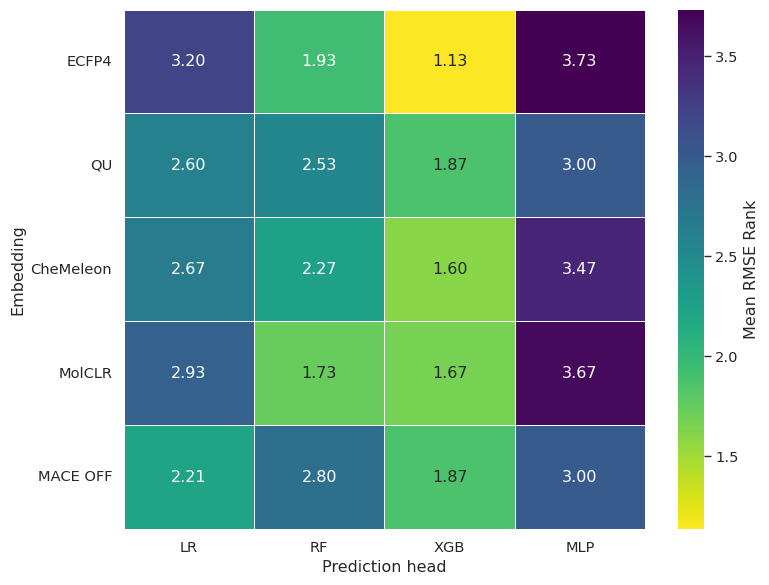

In [14]:
summary = (
    df_random_splits
    .groupby(["dataset", "embedding", "model", "split_method"], as_index=False)
    ["test_RMSE"]
    .agg(mean_RMSE="mean", std_RMSE="std")
)


summary["rank"] = (
    summary
    .groupby(["dataset", "embedding", "split_method"])["mean_RMSE"]
    .rank(method="dense", ascending=True)
)

model_order = ["LR", "RF", "XGB", "MLP"]
summary["model"] = pd.Categorical(
    summary["model"],
    categories=model_order,
    ordered=True,
)

heatmap_data = (
    summary
    .groupby(["embedding", "model"], observed=True)["rank"]
    .mean()
    .unstack("model")
    .reindex(columns=model_order)
)

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="viridis_r",  # lower/better ranks are green
    linewidths=0.5,
    cbar_kws={"label": "Mean RMSE Rank"},
    ax=ax,
)

ax.set_xlabel("Prediction head")
ax.set_ylabel("Embedding")
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

# Deeper dive: parity and/or residual plots to show where models succeed/fail

In [15]:
# code gets outputted to root directory instead of corresponding output folder. 
# it is wrong and I should fix but haven't yet. 

# generate predictions for xgboost models and save to paraquet files
!python ../05_PY_SCRIPTS/generate_xgb_predictions.py

/home/andre/anaconda3/envs/chem/lib/python3.11/site-packages/xgboost/core.py:377: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc >= 2.28) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=0/ckpts/hq_descriptor_model=xgboost_seed=0.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=1/ckpts/hq_descriptor_model=xgboost_seed=1.pkl
Processed CD/xgboost/hq_descriptor/split=random_seed0_modelseed=2/ckpts/hq_descriptor_model=xgboost_seed=2.pkl
Processed CD/xgboost/hq_descriptor/split=random_s

In [16]:
parquet_path = "../07_OUTPUTS/20260625/deep_dive_xgb_predictions.parquet"  # adjust
predictions_df = pd.read_parquet(parquet_path)

renamed_embeddings = {
    "hq_descriptor": "QU",
    "maceoff_large": "MACE OFF",
}
predictions_df["embedding"] = predictions_df["embedding"].map(renamed_embeddings)


renamed_models = {"xgboost": "XGB"}
renamed_dataset = {"CD": r"$\rho_{cryst}$"}
predictions_df["dataset"] = predictions_df["dataset"].map(renamed_dataset).fillna(predictions_df["dataset"])

desired_dataset_order = [
    r"$\rho_{cryst}$",
    "HOF",
    "IS"
]
predictions_df["dataset"] = pd.Categorical(predictions_df["dataset"], categories=desired_dataset_order, ordered=True)

predictions_df

,dataset,embedding,split_seed,model_seed,compound_id,y_true,y_pred
0,$\rho_{cryst}$,QU,0,0,O=C(OCC([N+](=O)[O-])([N+](=O)[O-])[N+](=O)[O-...,1.851000,1.833033
1,$\rho_{cryst}$,QU,0,0,O=C(CCN(CCC(=O)OCC([N+](=O)[O-])([N+](=O)[O-])...,1.703000,1.706970
2,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1cc([N+](=O)[O-])c(-c2c([N+](=O)[...,1.828000,1.738453
3,$\rho_{cryst}$,QU,0,0,O=[N+]([O-])c1ccc(CC([N+](=O)[O-])([N+](=O)[O-...,1.732000,1.705867
4,$\rho_{cryst}$,QU,0,0,Cn1nc([N+](=O)[O-])c(Nc2c([N+](=O)[O-])cc([N+]...,1.746000,1.755874
...,...,...,...,...,...,...,...
15995,IS,MACE OFF,4,4,O=[N+]([O-])c1cc([N+](=O)[O-])c(C=Cc2c([N+](=O...,2.257065,1.641250
15996,IS,MACE OFF,4,4,Nc1nc(N)n2nc(N)c([N+](=O)[O-])c2n1,3.688880,4.001578
15997,IS,MACE OFF,4,4,Cc1c([N+](=O)[O-])cc([N+](=O)[O-])c(C)c1[N+](=...,0.693147,0.926044
15998,IS,MACE OFF,4,4,Cc1c([N+](=O)[O-])c(C)c([N+](=O)[O-])c(O)c1[N+...,0.634718,1.383015


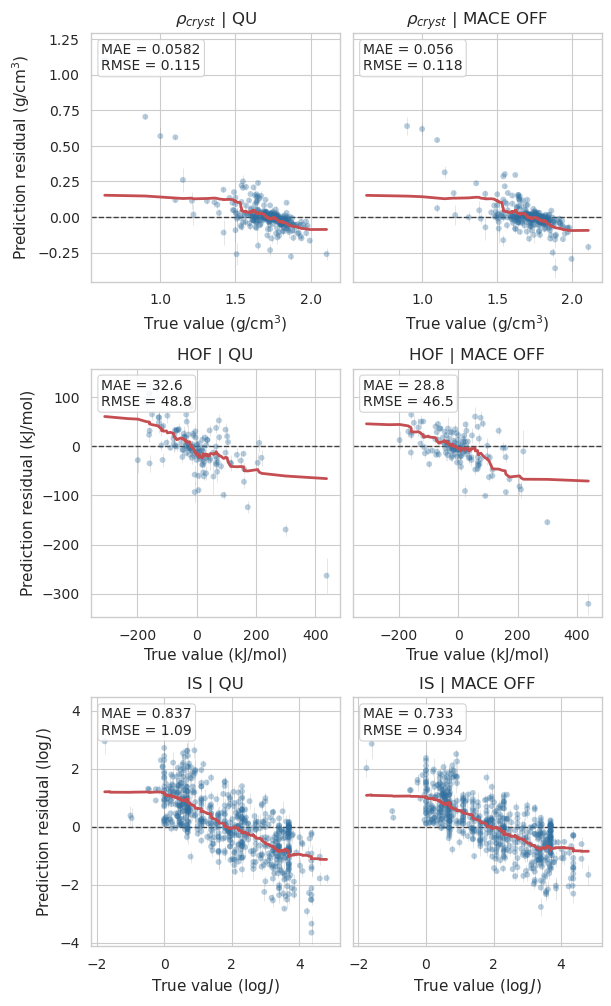

In [17]:
import importlib
import xgb_prediction_plots
importlib.reload(xgb_prediction_plots)

from xgb_prediction_plots import (
    aggregate_seed_predictions,
    plot_residual_grid,
    plot_parity_grid,
)

predictions_agg = aggregate_seed_predictions(predictions_df)
predictions_agg.head()

fig = plot_residual_grid(predictions_df, show_pred_std=True, use_aggregated=True, figsize=(6, 10))

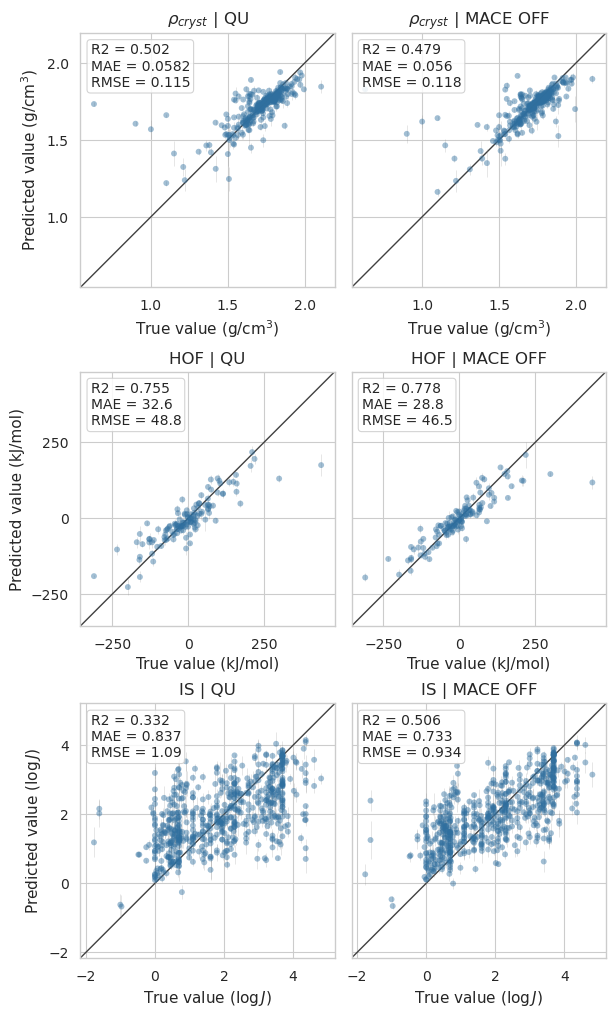

In [18]:
fig = plot_parity_grid(
    predictions_df,
    use_aggregated=True,
    color_by=None,
    show_pred_std=True,
    figsize=(6, 10),
)